# Modelo de sonrisa: sonríe / no sonríe

Decide si la persona **sonríe**.

En el juego, mantener la sonrisa **activa el turbo**.

**Datos**
* Recortes de boca de 64×64 (`datasets/sonrisa_recortes`) obtenidos con MediaPipe en el cuaderno `VC_P5_gestos_datasets.ipynb` a partir de **GENKI-4K**.

* Son 4.000 caras de internet con etiqueta sonrisa / no sonrisa; tras quitar duplicados y caras no detectadas quedan 3.956.

**Métodos comparados**
1. Píxeles + KNN (referencia mínima)
2. HOG + SVM
3. LBP + SVM
4. CNN pequeña (en color, con aumento de datos)
5. **MediaPipe `mouthSmile`** (sin entrenar) - media de los *blendshapes* `mouthSmileLeft` y `mouthSmileRight`.
6. **DeepFace `analyze`** (sin entrenar por nosotros) - probabilidad de la emoción *happy*.

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2
from collections import Counter
from skimage.feature import hog, local_binary_pattern
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import ConfusionMatrixDisplay

from utilidades_gestos import (carga_dataset, kfold_agrupado, tabla_resultados, metricas, f1_medio,
                               mide_latencia, ModeloGesto, guarda_resumen)

CLASES = ['no_sonrie', 'sonrie'] # etiqueta 1 = sonríe (clase positiva)
TAM = 64
ECUALIZAR = True
CARPETA = 'datasets/sonrisa_recortes'
ORIGINALES = 'datasets/sonrisa' 
FIGURAS = 'figuras'

---

## 1. Carga de datos y casi duplicados

GENKI-4K no indica la identidad de cada persona, pero son fotos de internet de personas en su gran mayoría distintas.

Para evitar que fotos **casi idénticas** queden una en entrenamiento y otra en test, se agrupan las caras completas muy parecidas con el mismo método que en el cuaderno de la boca:
1. Cada cara completa se reduce a 32×32 píxeles en color, se suaviza y se normaliza.
2. Se agrupan con **clustering jerárquico** (enlace medio, distancia coseno) con un umbral muy estricto de 0,02, para que solo se junten las fotos casi idénticas.

In [2]:
nombres = []
miniaturas = []
for clase in CLASES:
    for f in sorted(os.listdir(os.path.join(CARPETA, clase))):
        img = cv2.imread(os.path.join(ORIGINALES, clase, f))
        mini = cv2.GaussianBlur(cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32), (3, 3), 0)
        v = mini.ravel()
        miniaturas.append((v - v.mean()) / (v.std() + 1e-6))
        nombres.append(f)

# Fotos a menos de 0,02 de distancia coseno quedan en el mismo grupo
etiquetas_grupo = AgglomerativeClustering(n_clusters=None, distance_threshold=0.02, metric='cosine',
                                          linkage='average').fit_predict(np.array(miniaturas))
GRUPO = dict(zip(nombres, etiquetas_grupo))

X, y, grupos, rutas = carga_dataset(CARPETA, CLASES, TAM, grupo_de=GRUPO.get, ecualizar=ECUALIZAR)
X_color, _, _, _ = carga_dataset(CARPETA, CLASES, TAM, grupo_de=GRUPO.get, gris=False, ecualizar=ECUALIZAR) # CNN

tamanos = Counter(grupos)
duplicados = 0

for n in tamanos.values():
    if n > 1:
        duplicados += 1

print('Imágenes:', X.shape, '| por clase:', dict(zip(CLASES, np.bincount(y))))
print(f'Grupos: {len(tamanos)} | grupos con más de una imagen (casi duplicados): {duplicados}')

Imágenes: (3956, 64, 64) | por clase: {'no_sonrie': np.int64(1817), 'sonrie': np.int64(2139)}
Grupos: 3952 | grupos con más de una imagen (casi duplicados): 4


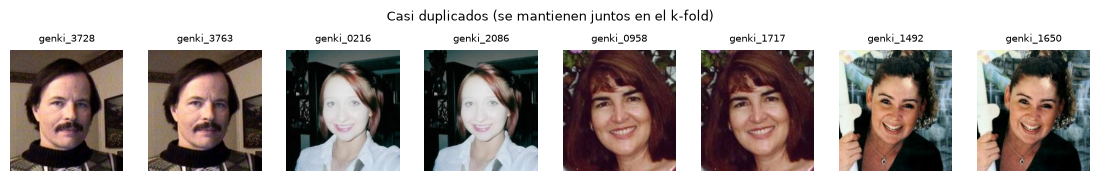

In [3]:
# Parejas de casi duplicados encontradas
pares = []
for g, n in tamanos.items():
    if n > 1:
        pares.append(g)

if pares:
    fig, axs = plt.subplots(1, 2 * len(pares), figsize=(2 * len(pares) * 1.4, 1.8), squeeze=False)
    col = 0

    for g in pares:
        for i in np.where(grupos == g)[0][:2]:
            orig = cv2.imread(os.path.join(ORIGINALES, CLASES[y[i]], os.path.basename(rutas[i])))
            axs[0, col].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
            axs[0, col].set_title(os.path.basename(rutas[i]).replace('.jpg', ''), fontsize=7)
            axs[0, col].axis('off')
            col += 1

    plt.suptitle('Casi duplicados (se mantienen juntos en el k-fold)', fontsize=9)
    plt.tight_layout()
    plt.show()

---

## 2. Descriptores HOG vs LBP

Al sonreír, las comisuras suben, los labios se estiran y suelen aparecer los dientes.

* HOG capta la curvatura de los labios.
* LBP la textura de los dientes.

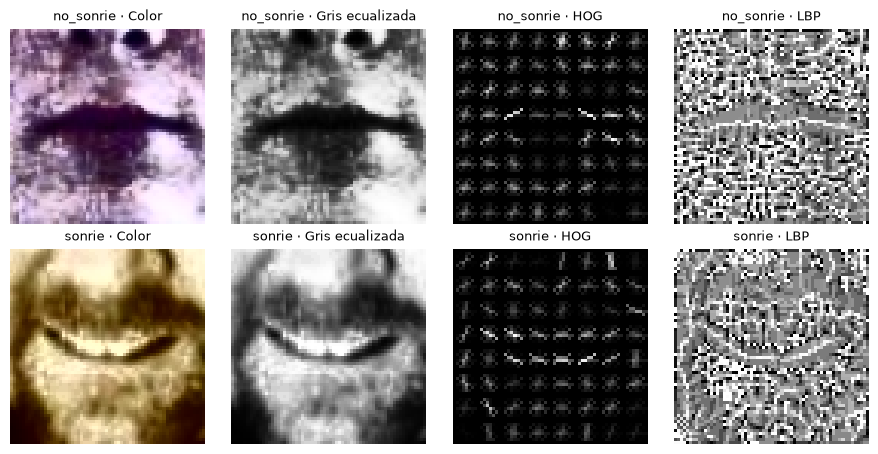

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(9, 4.6))

for fila, etiqueta in enumerate([0, 1]):
    i = np.where(y == etiqueta)[0][25]
    _, vis_hog = hog(X[i], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp = local_binary_pattern(X[i], 8, 1, method='nri_uniform')
    imgs = [cv2.cvtColor(X_color[i], cv2.COLOR_BGR2RGB), X[i], vis_hog, lbp]

    for ax, im, titulo in zip(axs[fila], imgs, ['Color', 'Gris ecualizada', 'HOG', 'LBP']):
        if im.ndim == 3:
            ax.imshow(im)
        else:
            ax.imshow(im, cmap='gray')
        ax.set_title(f'{CLASES[etiqueta]} · {titulo}', fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.savefig(f'{FIGURAS}/sonrisa_descriptores.png', dpi=120)
plt.show()

---

## 3. Validación cruzada k-fold

Igual que en la boca: HOG y LBP se calculan sobre la imagen en gris ecualizada, y la CNN recibe la imagen **en color** y se entrena 30 épocas con aumento de datos.

* Métricas respecto a la clase **sonríe**: una precisión baja activaría el turbo sin querer; un recall bajo, que no se active al sonreír.

In [5]:
METODOS = ['Píxeles + KNN', 'HOG + SVM', 'LBP + SVM', 'CNN']
res = kfold_agrupado(X, y, grupos, METODOS, k=5, X_cnn=X_color)
print()
tabla_resultados(res)

Fold 1: Píxeles + KNN F1=0.932 | HOG + SVM F1=0.936 | LBP + SVM F1=0.932 | CNN F1=0.890
Fold 2: Píxeles + KNN F1=0.919 | HOG + SVM F1=0.944 | LBP + SVM F1=0.935 | CNN F1=0.892
Fold 3: Píxeles + KNN F1=0.918 | HOG + SVM F1=0.939 | LBP + SVM F1=0.936 | CNN F1=0.896
Fold 4: Píxeles + KNN F1=0.915 | HOG + SVM F1=0.950 | LBP + SVM F1=0.938 | CNN F1=0.908
Fold 5: Píxeles + KNN F1=0.901 | HOG + SVM F1=0.929 | LBP + SVM F1=0.925 | CNN F1=0.871

Método                 Accuracy       Precisión          Recall              F1
Píxeles + KNN     0.913 ± 0.010   0.944 ± 0.007   0.892 ± 0.015   0.917 ± 0.010
HOG + SVM         0.935 ± 0.008   0.951 ± 0.011   0.928 ± 0.009   0.939 ± 0.007
LBP + SVM         0.928 ± 0.005   0.945 ± 0.010   0.922 ± 0.007   0.933 ± 0.005
CNN               0.877 ± 0.014   0.855 ± 0.026   0.933 ± 0.027   0.891 ± 0.012


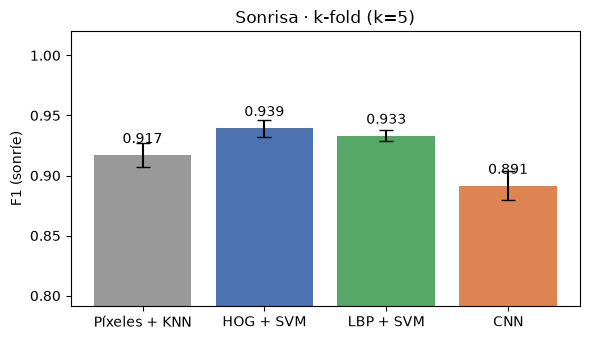

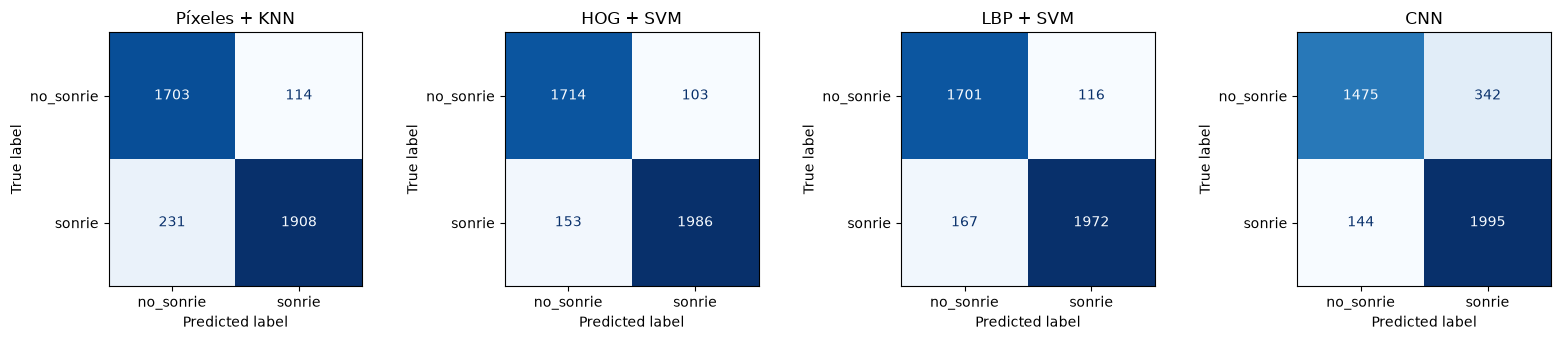

In [6]:
f1, f1_std = [], []

for m in METODOS:
    media, desviacion = f1_medio(res, m)
    f1.append(media)
    f1_std.append(desviacion)

plt.figure(figsize=(6, 3.5))
plt.bar(METODOS, f1, yerr=f1_std, capsize=5, color=['#999999', '#4C72B0', '#55A868', '#DD8452'])

for i, v in enumerate(f1):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center')

plt.ylim(min(f1) - 0.1, 1.02)
plt.ylabel('F1 (sonríe)')
plt.title('Sonrisa · k-fold (k=5)')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/sonrisa_kfold_f1.png', dpi=120)
plt.show()

fig, axs = plt.subplots(1, len(METODOS), figsize=(4 * len(METODOS), 3.5))

for ax, m in zip(axs, METODOS):
    ConfusionMatrixDisplay(res[m]['cm'], display_labels=CLASES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(m)

plt.tight_layout()
plt.savefig(f'{FIGURAS}/sonrisa_kfold_confusion.png', dpi=120)
plt.show()

---

## 4. MediaPipe y DeepFace

Se calculan dos puntuaciones sobre la **cara completa** de cada imagen:
- **MediaPipe**: media de `mouthSmileLeft` y `mouthSmileRight` (0–1).
- **DeepFace**: probabilidad de la emoción *happy* que devuelve `DeepFace.analyze(actions=['emotion'])` (0–100, se pasa a 0–1).

DeepFace detecta y recorta la cara con su detector `opencv`. En una prueba previa, pasándole la foto completa sin detectar (`detector_backend='skip'`), el F1 caía a 0,56, casi al azar, porque su modelo de emociones (48×48 píxeles) espera una cara recortada y ajustada, no la foto con fondo.

Igual que con `jawOpen` en la boca, en cada fold se elige el umbral que maximiza el F1 en las imágenes de entrenamiento y se evalúa en las de test, con **los mismos folds** que los modelos entrenados.


DeepFace: 22.2 ms por imagen (mediana)


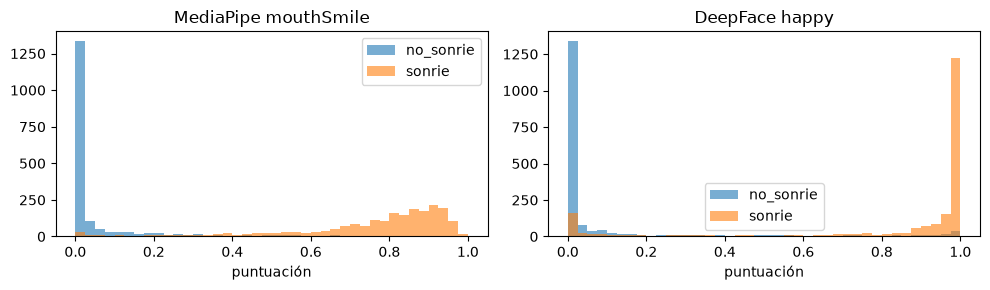

In [7]:
import mediapipe as mp
from deepface import DeepFace

opciones = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path='face_landmarker.task'),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=1, output_face_blendshapes=True)

sonrisa_mp = np.zeros(len(y))
feliz_df = np.zeros(len(y))
t_deepface = []

with mp.tasks.vision.FaceLandmarker.create_from_options(opciones) as detector:
    for i, r in enumerate(rutas):
        orig = cv2.imread(os.path.join(ORIGINALES, CLASES[y[i]], os.path.basename(r)))

        # MediaPipe: media de la sonrisa izquierda y derecha
        res_mp = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                          data=cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)))
        if res_mp.face_blendshapes:
            bs = {}
            for c in res_mp.face_blendshapes[0]:
                bs[c.category_name] = c.score
            sonrisa_mp[i] = (bs['mouthSmileLeft'] + bs['mouthSmileRight']) / 2

        # DeepFace: probabilidad de la emoción happy
        t0 = time.perf_counter()
        an = DeepFace.analyze(orig, actions=['emotion'], detector_backend='opencv',
                              enforce_detection=False, silent=True)
        t_deepface.append(time.perf_counter() - t0)
        feliz_df[i] = an[0]['emotion']['happy'] / 100

ms_deepface = 1000 * np.median(t_deepface)
print(f'DeepFace: {ms_deepface:.1f} ms por imagen (mediana)')

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

for ax, puntos, titulo in zip(axs, [sonrisa_mp, feliz_df], ['MediaPipe mouthSmile', 'DeepFace happy']):
    for etiqueta in [0, 1]:
        ax.hist(puntos[y == etiqueta], bins=40, range=(0, 1), alpha=0.6, label=CLASES[etiqueta])
    ax.set_title(titulo); ax.set_xlabel('puntuación'); ax.legend()

plt.tight_layout()
plt.savefig(f'{FIGURAS}/sonrisa_referencias_hist.png', dpi=120)
plt.show()

In [ ]:
def mejor_umbral(puntos, etiquetas):
    """Umbral entre 0,01 y 0,99 que da el mayor F1 con las imágenes de entrenamiento."""
    mejor, mejor_f1 = None, -1

    for u in np.linspace(0.01, 0.99, 99):
        f1 = metricas(etiquetas, (puntos >= u).astype(int))['f1']
        if f1 > mejor_f1:
            mejor, mejor_f1 = u, f1
    return mejor

skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

for nombre, puntos in [('MediaPipe mouthSmile', sonrisa_mp), ('DeepFace happy', feliz_df)]:
    folds, umbrales = [], []

    for tr, te in skf.split(X, y, grupos):
        u = mejor_umbral(puntos[tr], y[tr])
        umbrales.append(u)
        folds.append(metricas(y[te], (puntos[te] >= u).astype(int)))

    res[nombre] = {'folds': folds}
    print(f'{nombre}: umbrales por fold {np.round(umbrales, 2)}')

print()
tabla_resultados(res)

MediaPipe mouthSmile: umbrales por fold [0.32 0.32 0.31 0.32 0.29]
DeepFace happy: umbrales por fold [0.17 0.18 0.19 0.31 0.19]

Método                 Accuracy       Precisión          Recall              F1
Píxeles + KNN     0.913 ± 0.010   0.944 ± 0.007   0.892 ± 0.015   0.917 ± 0.010
HOG + SVM         0.935 ± 0.008   0.951 ± 0.011   0.928 ± 0.009   0.939 ± 0.007
LBP + SVM         0.928 ± 0.005   0.945 ± 0.010   0.922 ± 0.007   0.933 ± 0.005
CNN               0.877 ± 0.014   0.855 ± 0.026   0.933 ± 0.027   0.891 ± 0.012
MediaPipe mouthSmile   0.938 ± 0.009   0.944 ± 0.011   0.941 ± 0.009   0.942 ± 0.008
DeepFace happy    0.868 ± 0.006   0.881 ± 0.017   0.875 ± 0.015   0.878 ± 0.004


---

## 5. Modelos finales y latencia

Se entrenan los modelos con todas las imágenes y se mide el tiempo de clasificar **un recorte de boca** (incluyendo el descriptor), que es lo que se hará en cada fotograma del juego.

* DeepFace se mide por cara, porque incluye su propia detección de la cara.
* Después se muestran ejemplos de errores de HOG + SVM y de la CNN, entrenados con 4 folds y evaluados en el quinto.

In [9]:
modelos = {
    'HOG + SVM': ModeloGesto.entrena('hog', X, y, TAM, True, CLASES, ecualizar=ECUALIZAR),
    'LBP + SVM': ModeloGesto.entrena('lbp', X, y, TAM, True, CLASES, ecualizar=ECUALIZAR),
    'CNN': ModeloGesto.entrena('cnn', X_color, y, TAM, False, CLASES, ecualizar=ECUALIZAR),
}

recortes_bgr = []

for r in rutas[::10][:300]:
    recortes_bgr.append(cv2.imread(r))

latencias = {}

for n, mg in modelos.items():
    latencias[n] = mide_latencia(mg, recortes_bgr)

for n, ms in latencias.items():
    print(f'{n:12s} {ms:6.2f} ms por recorte de boca')
print(f"{'DeepFace':12s} {ms_deepface:6.2f} ms por cara (detección con opencv + emoción)")

HOG + SVM      3.31 ms por recorte de boca
LBP + SVM      2.86 ms por recorte de boca
CNN            1.01 ms por recorte de boca
DeepFace      22.24 ms por cara (detección con opencv + emoción)


HOG + SVM: 51 errores de 792 en el fold 1
CNN: 94 errores de 792 en el fold 1


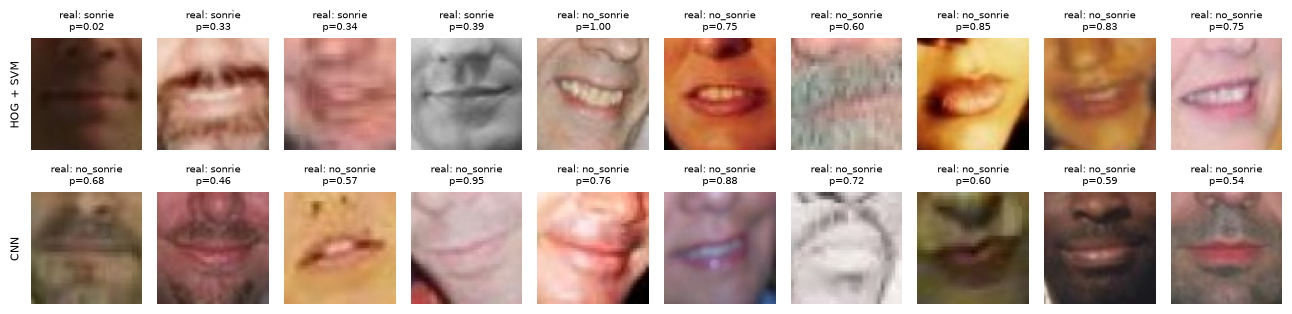

In [10]:
# Ejemplos mal clasificados por HOG + SVM y por la CNN en el primer fold de test
tr, te = next(skf.split(X, y, grupos))
errores_por_modelo = {}

for nombre, tipo, Xm, gris in [('HOG + SVM', 'hog', X, True), ('CNN', 'cnn', X_color, False)]:
    mg = ModeloGesto.entrena(tipo, Xm[tr], y[tr], TAM, gris, CLASES, ecualizar=ECUALIZAR)
    p = mg.prob_lote(Xm[te])
    errores_por_modelo[nombre] = (te[(p >= 0.5).astype(int) != y[te]], p, te)

fig, axs = plt.subplots(2, 10, figsize=(13, 3.4))

for fila, (nombre, (err, p, idx_te)) in enumerate(errores_por_modelo.items()):
    sel = np.random.default_rng(0).choice(err, min(10, len(err)), replace=False)

    for col, i in enumerate(sel):
        prob = p[np.where(idx_te == i)[0][0]]
        axs[fila, col].imshow(cv2.cvtColor(cv2.imread(rutas[i]), cv2.COLOR_BGR2RGB))
        axs[fila, col].set_title(f'real: {CLASES[y[i]]}\np={prob:.2f}', fontsize=7)
        axs[fila, col].axis('off')

    axs[fila, 0].text(-6, 32, nombre, fontsize=8, rotation=90, va='center', ha='right')
    print(f'{nombre}: {len(err)} errores de {len(idx_te)} en el fold 1')

plt.tight_layout()
plt.savefig(f'{FIGURAS}/sonrisa_errores.png', dpi=120)
plt.show()

---

## 6. Modelo elegido

**Criterio de elección**: igual que en la boca, entre los modelos **entrenados por nosotros**, el de mayor F1 en el k-fold. Si dos modelos quedan a menos de 0,005 de F1 (diferencia menor que la variación entre folds), se elige el más rápido.

> MediaPipe `mouthSmile` y DeepFace se muestran como referencia, pero no se eligen porque la práctica pide un modelo entrenado propio.

- `figuras/sonrisa_resumen.png`: comparación de métodos con el elegido resaltado con una estrella.
- `resultados/sonrisa_resumen.md` y `.json`: tabla, modelo elegido y motivo.

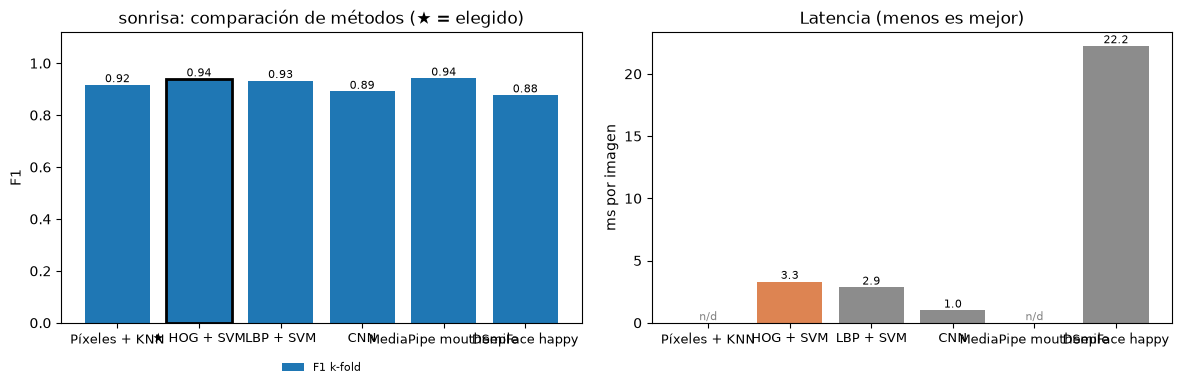

## Modelo de sonrisa

| Método | F1 k-fold | ms por imagen |
|---|---|---|
| Píxeles + KNN | 0.917 | — |
| **HOG + SVM** ★ | 0.939 | 3.3 |
| LBP + SVM | 0.933 | 2.9 |
| CNN | 0.891 | 1.0 |
| MediaPipe mouthSmile | 0.942 | — |
| DeepFace happy | 0.878 | 22.2 |

**Modelo elegido:** HOG + SVM

**Motivo:** Mayor F1 en el k-fold entre los modelos entrenados: 0.939, con 3.3 ms por recorte. Como referencia, MediaPipe mouthSmile obtiene 0.942 y DeepFace happy 0.878 (22 ms por cara).

Guardado: figuras\sonrisa_resumen.png, resultados/sonrisa_resumen.md y .json
Modelos guardados en modelos/  ->  el juego usará modelos/sonrisa_hog


In [11]:
# F1 medio en el k-fold de cada método
f1k = {}
for m in res:
    f1k[m] = f1_medio(res, m)[0]

# Mejor F1 entre los modelos entrenados
mejor_f1 = -1
for m in modelos:
    if f1k[m] > mejor_f1:
        mejor_f1 = f1k[m]

# Los que se quedan a menos de 0,005 del mejor (empate)
candidatos = []
for m in modelos:
    if mejor_f1 - f1k[m] < 0.005:
        candidatos.append(m)

# El más rápido
elegido, ms_elegido = None, float('inf')

for m in candidatos:
    if latencias[m] < ms_elegido:
        elegido, ms_elegido = m, latencias[m]

filas = [{'Método': 'Píxeles + KNN', 'F1 k-fold': f1k['Píxeles + KNN'], 'ms': None}]

for m in modelos:
    filas.append({'Método': m, 'F1 k-fold': f1k[m], 'ms': latencias[m]})

filas.append({'Método': 'MediaPipe mouthSmile', 'F1 k-fold': f1k['MediaPipe mouthSmile'], 'ms': None})
filas.append({'Método': 'DeepFace happy', 'F1 k-fold': f1k['DeepFace happy'], 'ms': ms_deepface})

if len(candidatos) > 1:
    otros = []
    for c in candidatos:
        if c != elegido:
            otros.append(c)
    texto_empate = (f" (empatado a menos de 0,005 con {', '.join(otros)}, "
                    f"se elige por ser el más rápido)")
else:
    texto_empate = ''

motivo = (f"Mayor F1 en el k-fold entre los modelos entrenados: {f1k[elegido]:.3f}{texto_empate}, "
          f"con {latencias[elegido]:.1f} ms por recorte. Como referencia, MediaPipe mouthSmile obtiene "
          f"{f1k['MediaPipe mouthSmile']:.3f} y DeepFace happy {f1k['DeepFace happy']:.3f} "
          f"({ms_deepface:.0f} ms por cara).")

guarda_resumen('sonrisa', filas, elegido, motivo, ['F1 k-fold'])

for n, mg in modelos.items():
    mg.guarda(f'modelos/sonrisa_{mg.tipo}')

print('Modelos guardados en modelos/  ->  el juego usará modelos/sonrisa_' + modelos[elegido].tipo)

---

## 7. Facilidad de uso y coste

Comparamos los modelos clásicos y las redes neuronales no solo por sus resultados, sino también por su **facilidad de uso** y su **rapidez**.

Para cada método se recoge:

- **Tiempo de entrenamiento** medio por fold (en la CPU, sin GPU), incluida la búsqueda en rejilla de la SVM.
- **Tiempo de predicción** por imagen del modelo final, que es lo que importa en el juego.
- **Tamaño** del modelo guardado.
- **Qué hay que ajustar** para usarlo.

Se guarda en `resultados/sonrisa_facilidad.md` y `figuras/sonrisa_facilidad.png`.

## Facilidad de uso y coste: sonrisa

| Método | Entrenamiento por fold (s) | Predicción (ms/imagen) | Tamaño (MB) | Qué hay que ajustar | Observaciones |
|---|---|---|---|---|---|
| Píxeles + KNN | 0.3 | — | — | k (vecinos) | No entrena: guarda todas las imágenes y compara con todas al predecir. |
| HOG + SVM | 57.7 | 3.3 | 21.57 | celdas, orientaciones, bloques + C y gamma (rejilla) | Hay que diseñar el descriptor; la búsqueda en rejilla de la SVM multiplica el tiempo de entrenamiento. |
| LBP + SVM | 29.1 | 2.9 | 13.00 | celdas, vecinos, radio, tipo de patrón + C y gamma (rejilla) | Igual que HOG; el descriptor es más lento de calcular. |
| CNN | 33.0 | 1.0 | 0.39 | arquitectura, épocas, lote, optimizador, aumento de datos | No hay que diseñar descriptores, pero sí la red; necesita TensorFlow. Su tiempo de entrenamiento depende de las épocas, no del número de vectores soporte, y en CPU es similar al de la SVM con búsqueda en rejilla. |
| MediaPipe mouthSmile | 0.0 | — | — | solo el 

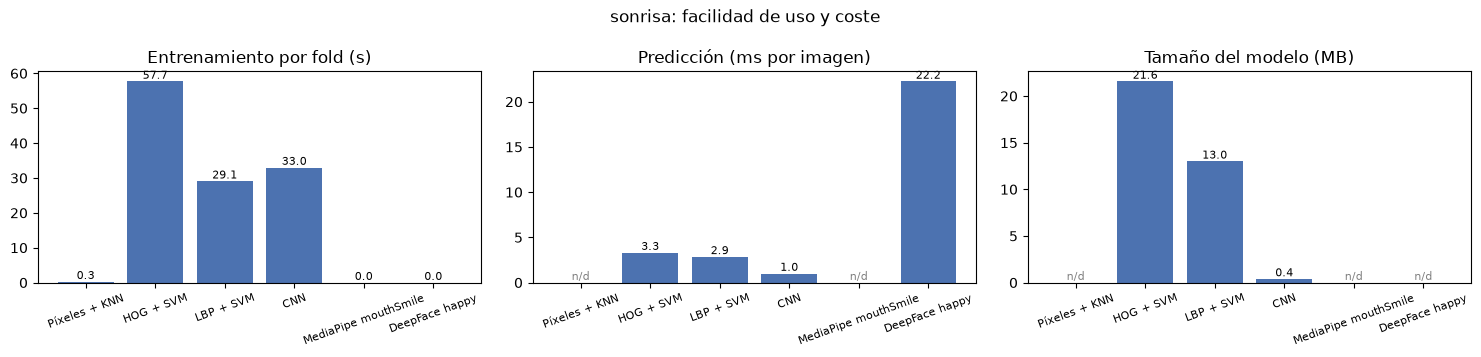

In [12]:
from utilidades_gestos import tabla_facilidad
facilidad = tabla_facilidad('sonrisa', res, latencias,
                            referencias={'MediaPipe mouthSmile': None, 'DeepFace happy': ms_deepface})

---

## 8. Conclusiones

| Método | F1 k-fold | ms |
|---|---|---|
| Píxeles + KNN | 0,917 ± 0,010 | — |
| **HOG + SVM** ★ | **0,939 ± 0,007** | 3,3 por recorte |
| LBP + SVM | 0,933 ± 0,005 | 2,9 por recorte |
| CNN (color, con aumento) | 0,891 ± 0,012 | 1,0 por recorte |
| MediaPipe `mouthSmile` (sin entrenar) | 0,942 ± 0,008 | — |
| DeepFace `happy` (sin entrenar por nosotros) | 0,878 ± 0,004 | 22 por cara |

Los F1 se repiten en cada ejecución; la latencia varía con la carga del ordenador.

La comparación final y el modelo elegido quedan guardados en `figuras/sonrisa_resumen.png` y `resultados/sonrisa_resumen.md`.

1. **Los descriptores clásicos vuelven a ganar**: HOG + SVM (0,939) y LBP + SVM (0,933) superan a la CNN (0,891), que tiene un recall alto pero una precisión baja (0,855): tiende a ver sonrisas donde no las hay. Con unas 3.200 imágenes de entrenamiento por fold, una red pequeña entrenada desde cero no supera a una SVM con buenos descriptores.
2. **La sonrisa es más difícil que la boca abierta** (0,94 frente a 0,98): hay sonrisas leves sin dientes, bocas neutras con los dientes visibles y caras de baja resolución, oscuras o con barba.
    * Algunos de los "errores" son etiquetas discutibles de GENKI (caras etiquetadas como no sonrisa que parecen sonreír), lo que pone un techo a cualquier método.
3. **MediaPipe `mouthSmile` iguala al mejor modelo entrenado** (0,942 frente a 0,939), igual que pasaba con `jawOpen` en la boca.
4. **DeepFace queda por detrás** (0,878) y es **unas 7 veces más lento** que HOG + SVM (22 ms por cara, incluyendo su propia detección de la cara).
    * DeepFace estima la emoción *happy*, que no es exactamente lo mismo que sonreír: una sonrisa leve o de compromiso no siempre se interpreta como alegría.
5. **Importancia del recorte para DeepFace**: pasándole la foto completa sin detectar la cara (`detector_backend='skip'`), su F1 caía a 0,56, casi al azar. Con su detector `opencv` sube a 0,878. Igual que en los ojos, **el encuadre de la imagen que recibe el modelo es tan importante como el propio modelo**.

6. **Facilidad de uso y coste** (en CPU, sin GPU): con más imágenes (unas 3.200 por fold) la SVM se encarece. HOG + SVM tarda 58 s por fold en entrenar y su modelo ocupa **21,6 MB**, porque guarda los vectores soporte; la CNN tarda 33 s, predice en 1,0 ms y ocupa 0,39 MB.
    * El coste de la SVM crece con el tamaño del dataset, mientras que el de la CNN depende sobre todo del número de épocas.
    * DeepFace no se entrena, pero es la más lenta al predecir (22 ms por cara) y depende de un detector de caras; MediaPipe `mouthSmile` sale "gratis" con los landmarks.

> El modelo elegido ha sido **HOG + SVM** (`modelos/sonrisa_hog`), el de mayor F1 entre los entrenados y unas 7 veces más rápido que DeepFace.

---